# Poroelastic sensitivity kernels — Morency et al. (2009) with `sweep`'s Biot

Morency, Luo & Tromp (2009) computed finite-frequency **traveltime sensitivity kernels** for Biot's
poroelastic waves — fast P (P<sub>I</sub>), slow P (P<sub>II</sub>) and S — with an adjoint
spectral-element code, and showed them in three parameterizations: eight **primary** kernels (ρ, ρ<sub>f</sub>,
m, b = η/k, B, C, M, μ<sub>fr</sub>), eight **density-normalised** kernels, and seven **wave-speed** kernels.

Here the same kernels come from `sweep` without writing an adjoint: `Biot` is differentiable, so
`torch.autograd` gives the exact gradient of a cross-correlation traveltime with respect to its eight
coefficient fields, and the chain rule through each parameterization's map gives the three families.

| | Morency et al. (2009) | this notebook |
|---|---|---|
| model | homogeneous 10 km × 4 km, free surface on top | the same, open-pore free surface |
| source / receiver | point force, 2 km deep, 5 km apart | the same, dx = 10 m |
| kernels | adjoint SEM | `torch.autograd` through `Biot` |

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline
from scipy.ndimage import gaussian_filter
from scipy.optimize import minimize_scalar
from sweep.equations import Biot
from sweep.equations.biot import biot_from_rock
from sweep.propagator.torch import PropTorch
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False          # eager stencils in full FP32
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV, "| torch", torch.__version__)

device: cuda | torch 2.9.1+cu128


## 1. Media (Table 1 of the paper)

Three homogeneous rocks with grains of 2650 kg/m³ and 12.2 GPa, a 9.6 GPa frame and a tortuosity of 2. The
S/SS model has φ = 0.1; the P model φ = 0.3 with a stiff fluid that makes the slow P wave fast and
propagating. The fourth is the P model with a viscous fluid (η = 10⁻³ Pa·s, k = 10⁻¹⁰ m²): the low-frequency
regime, where the slow P wave diffuses. `biot_from_rock` turns each rock into the eight coefficients
`[H, μ, C, M, ρ, ρ_f, m, b]`; the phase speeds at 3 Hz reproduce the paper's.

In [2]:
ROCK = dict(rho_s=2650.0, rho_f=880.0, tort=2.0, k_s=12.2e9, k_d=9.6e9)
MODELS = {   # phi, fluid modulus, frame shear modulus, viscosity, permeability; paper's listed speeds
    "S&SS":      dict(phi=0.1, k_f=1.985e9, mu=5.1e9, eta=0.0, perm=1.0, listed=(2639, 961, 1449)),
    "P":         dict(phi=0.3, k_f=6.0e9, mu=1.8e9, eta=0.0, perm=1.0, listed=(2484, 1972, 952)),
    "P viscous": dict(phi=0.3, k_f=6.0e9, mu=1.8e9, eta=1e-3, perm=1e-10, listed=(2482, 280, 922)),
}
F0 = 3.0

def coefficients(name):
    p = MODELS[name]
    return [float(v) for v in biot_from_rock(k_s=ROCK["k_s"], rho_s=ROCK["rho_s"], k_f=p["k_f"], rho_f=ROCK["rho_f"],
                                             eta=p["eta"], k_d=ROCK["k_d"], mu=p["mu"], phi=p["phi"],
                                             kappa=p["perm"], tortuosity=ROCK["tort"])]

def phase_speeds(c, f=F0):
    # fast P, slow P, S phase speeds; the drag b enters as an imaginary fluid mass m + i b / w
    h, mu, cc, bm, rho, rho_f, m, b = c
    me = m + 1j*b/(2*np.pi*f)
    a, bq, cq = rho*me - rho_f**2, h*me + bm*rho - 2*cc*rho_f, h*bm - cc**2
    disc = np.sqrt(bq*bq - 4*a*cq + 0j)
    v2 = np.array([(bq + disc)/(2*a), (bq - disc)/(2*a), mu/(rho - rho_f**2/me)])
    v = 1/np.real(1/np.sqrt(v2))
    return v if v[0] >= v[1] else v[[1, 0, 2]]

for name in MODELS:
    c = coefficients(name)
    print("%-10s  H %.2f  mu %.2f  C %.2f  M %.2f GPa | rho %.0f  m %.0f  b %.0e | P_I %.0f  P_II %.0f  S %.0f m/s  (paper %s)"
          % (name, c[0]/1e9, c[1]/1e9, c[2]/1e9, c[3]/1e9, c[4], c[6], c[7], *phase_speeds(c), MODELS[name]["listed"]))

S&SS        H 17.16  mu 5.10  C 3.57  M 16.76 GPa | rho 2473  m 17600  b 0e+00 | P_I 2639  P_II 961  S 1449 m/s  (paper (2639, 961, 1449))
P           H 13.06  mu 1.80  C 4.97  M 23.32 GPa | rho 2119  m 5867  b 0e+00 | P_I 2484  P_II 1972  S 952 m/s  (paper (2484, 1972, 952))
P viscous   H 13.06  mu 1.80  C 4.97  M 23.32 GPa | rho 2119  m 5867  b 1e+07 | P_I 2483  P_II 283  S 922 m/s  (paper (2482, 280, 922))


## 2. Geometry, source and the forward problem

A point force acts on the bulk and on the fluid with the same amplitude (the paper's and SPECFEM2D's
convention). In `Biot`'s velocity–flux variables that is an injection into the solid velocity **v** and
the Darcy flux **q** with weights `(m − ρ_f, ρ − ρ_f)/(ρm − ρ_f²)` — two propagators, summed. The source
time function is the first derivative of a Gaussian of 3 Hz; it reproduces the waveforms of the paper's
Figs 2 and 5. Arrival times of the direct and free-surface-reflected phases come from the phase speeds.

In [3]:
LX, LZ, DX, DT, T_END, T0 = 10000.0, 4000.0, 10.0, 1e-3, 5.6, 0.5
NX, NZ, NT = int(LX/DX), int(LZ/DX), int(T_END/DT)
SRC_XZ, REC_XZ = (2500.0, 2000.0), (7500.0, 2000.0)             # (x, depth)
SRC = np.array([[int(SRC_XZ[0]/DX), int(SRC_XZ[1]/DX)]])
REC = np.array([[[int(REC_XZ[0]/DX), int(REC_XZ[1]/DX)]]])
t = np.arange(NT)*DT - T0
STF = -t*np.exp(-(np.pi*F0*t)**2)*np.sqrt(2.0)*np.pi*F0*np.exp(0.5)  # first derivative of a Gaussian
T_REC = (np.arange(NT) + 1)*DT                                   # record times (velocity at the half step)

PROPS = {f: PropTorch(Biot(spatial_order=4, device=DEV), shape=(NZ, NX), source_type=[f], receiver_type=["vx", "vz"],
                      abcn=80, free_surface=True, dh=DX, dt=DT, device=DEV, backend="torch", impl="eager")
         for f in ("vx", "vz", "qx", "qz")}

def record(c, ms, comp):
    # solid velocity (nt, 2) at the receiver for the force along comp ("x" or "z")
    h, mu, cc, bm, rho, rho_f, m, b = c
    det = rho*m - rho_f**2
    out = 0.0
    for f, a in ((f"v{comp}", (m - rho_f)/det), (f"q{comp}", (rho - rho_f)/det)):
        w = torch.from_numpy(STF*a*1e10*DT/DX**2).float()
        out = out + PROPS[f](w, SRC, REC, models=ms, max_vel=2700.0, pml_freq=F0)[0, :, 0, :]
    return out

def fields(c):
    return [torch.full((NZ, NX), v, dtype=torch.float32, device=DEV) for v in c]

def arrivals(c):
    vp1, vp2, vs = phase_speeds(c)
    v = {"PI": vp1, "PII": vp2, "S": vs}
    off, h = REC_XZ[0] - SRC_XZ[0], SRC_XZ[1]
    out = {k: off/val for k, val in v.items()}
    for name, (a, b) in {"PIPI": ("PI", "PI"), "SS": ("S", "S"), "PIIPII": ("PII", "PII"), "PIS": ("PI", "S"),
                         "PIIS": ("PII", "S"), "PIPII": ("PI", "PII")}.items():
        out[name] = float(minimize_scalar(lambda x: np.hypot(x, h)/v[a] + np.hypot(off - x, h)/v[b],
                                          bounds=(0.0, off), method="bounded").fun)
    return out

## 3. Seismograms

The z-component for a z-force in the S/SS model (the paper's Fig. 2) and the x-component for an x-force in
the P model (Fig. 5), with the arrival times of the labelled phases. Times are measured from the source
time function's centre.

sweep: compiling the eager time step with torch.compile; the first forward/backward pass takes longer (seconds to a few minutes, once per grid size, cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


two forward runs in 35 s


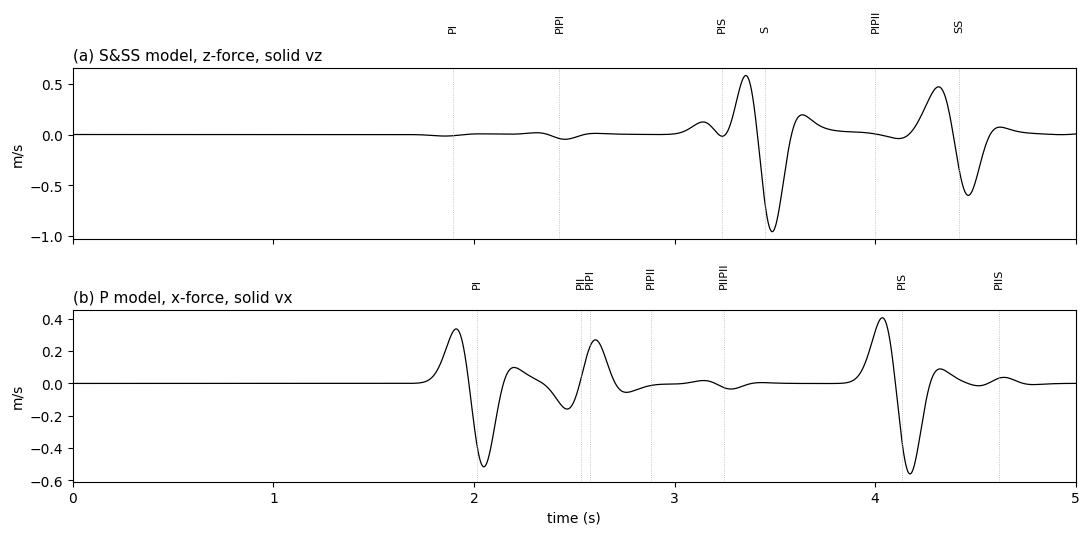

In [4]:
t0 = time.time()
with torch.no_grad():
    rec_s = record(coefficients("S&SS"), fields(coefficients("S&SS")), "z").cpu().numpy()
    rec_p = record(coefficients("P"), fields(coefficients("P")), "x").cpu().numpy()
print(f"two forward runs in {time.time() - t0:.0f} s")
fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, tr, name, lab in ((axs[0], rec_s[:, 1], "S&SS", "(a) S&SS model, z-force, solid vz"),
                          (axs[1], rec_p[:, 0], "P", "(b) P model, x-force, solid vx")):
    ax.plot(T_REC - T0, tr, "k", lw=0.9)
    top = np.abs(tr).max()
    for ph, ta in arrivals(coefficients(name)).items():
        if ta < 5:
            ax.axvline(ta, color="0.7", lw=0.6, ls=":")
            ax.text(ta, 1.05*top, ph, rotation=90, fontsize=8, ha="center", va="bottom")
    ax.set_title(lab, fontsize=11, loc="left"); ax.set_ylabel("m/s")
axs[1].set_xlabel("time (s)"); axs[1].set_xlim(0, 5)
fig.tight_layout(); plt.show()

## 4. Traveltime kernels by automatic differentiation

The cross-correlation traveltime of one Welch-windowed arrival on one solid-displacement component, to
first order, is the linear functional `δT = ∫ w u̇₀ δu dt / N` with `N = ∫ w u₀ ü₀ dt` (Tromp et al. 2005,
the paper's eq. 75). Writing it as a loss whose gradient is `δT/δc` and back-propagating through the
simulation gives the derivative with respect to each of the eight coefficient fields; per unit area and
multiplied by the parameter it is the kernel, `δT = Σ ∫ K_x δln x dA`.

Each family is a reparameterization of the same eight coefficients — e.g. the density-normalised one
uses ρ, ρ<sub>f</sub>, φ/c, B/ρ, C/ρ<sub>f</sub>, M/m, μ/ρ, b and the wave-speed one ρ, ρ<sub>f</sub>,
φ/c, the three phase speeds and the fast-wave amplitude ratio r<sub>I</sub>. Its kernels are a
vector–Jacobian product of the coefficient gradient through that map, i.e. the exact chain rule.

In [5]:
COEF = ["H", "mu", "C", "M", "rho", "rho_f", "m", "b"]
FAMILIES = {"primary":   ["rho", "rho_f", "m", "b", "B", "C", "M", "mufr"],
            "density":   ["rho", "rho_f", "phic", "Bbar", "Cbar", "Mbar", "mubar", "b"],
            "wavespeed": ["rho", "rho_f", "phic", "cpI", "cpII", "cs", "rI", "b"]}

def to_family(fam, c):
    h, mu, cc, bm, rho, rho_f, m, b = c
    big_b = h - 4.0/3.0*mu
    if fam == "primary":
        return [rho, rho_f, m, b, big_b, cc, bm, mu]
    if fam == "density":
        return [rho, rho_f, rho_f/m, big_b/rho, cc/rho_f, bm/m, mu/rho, b]
    a, bq = rho*m - rho_f**2, h*m + bm*rho - 2*cc*rho_f
    disc = torch.sqrt(bq*bq - 4*a*(h*bm - cc*cc))
    g, s0 = (rho*cc - rho_f*h)/m, h - rho*bm/m
    r_i = (s0 + torch.sqrt(s0*s0 + 4*(cc - rho_f*bm/m)*g))/(2*g)       # fast-wave amplitude ratio U/W
    return [rho, rho_f, rho_f/m, torch.sqrt((bq + disc)/(2*a)), torch.sqrt((bq - disc)/(2*a)),
            torch.sqrt(mu/(rho - rho_f**2/m)), r_i, b]

def from_family(fam, y):
    if fam == "primary":
        rho, rho_f, m, b, big_b, cc, bm, mufr = y
        return [big_b + 4.0/3.0*mufr, mufr, cc, bm, rho, rho_f, m, b]
    if fam == "density":
        rho, rho_f, phic, bbar, cbar, mbar, mubar, b = y
        m = rho_f/phic
        return [rho*(bbar + 4.0/3.0*mubar), rho*mubar, rho_f*cbar, m*mbar, rho, rho_f, m, b]
    rho, rho_f, phic, cp1, cp2, cs, r, b = y
    m = rho_f/phic
    a1, a2 = cp1*cp1, cp2*cp2
    u1, u2, n = rho*r + rho_f, rho_f*r + m, rho*r*r + 2*rho_f*r + m
    return [a2*rho + (a1 - a2)*u1*u1/n, cs*cs*(rho - rho_f*rho_f/m), a2*rho_f + (a1 - a2)*u1*u2/n,
            a2*m + (a1 - a2)*u2*u2/n, rho, rho_f, m, b]

def family_kernels(c, grads):
    cf = [torch.full((NZ, NX), v, dtype=torch.float64) for v in c]
    g = [x.double().cpu()/DX**2 for x in grads]
    out = {}
    for fam in FAMILIES:
        y = [v.clone().requires_grad_() for v in to_family(fam, cf)]
        back = from_family(fam, y)
        assert all(torch.allclose(u.detach(), v, rtol=1e-9) for u, v in zip(back, cf)), fam
        vjp = torch.autograd.grad(back, y, grad_outputs=g, allow_unused=True)
        out[fam] = {p: (yy.detach()*(jj if jj is not None else torch.zeros_like(yy))).numpy()
                    for p, yy, jj in zip(FAMILIES[fam], y, vjp)}
    return out

def welch(t_arr, pre=0.25, post=0.35):
    t1, t2 = T0 + t_arr - pre, T0 + t_arr + post
    x = 2*(T_REC - t1)/(t2 - t1) - 1
    return np.where((T_REC >= t1) & (T_REC <= t2), 1 - x*x, 0.0)

def kernels(model, comp, phase):
    c = coefficients(model)
    w = torch.from_numpy(welch(arrivals(c)[phase])).to(DEV)
    ms = [f.requires_grad_() for f in fields(c)]
    v = record(c, ms, comp)[:, {"x": 0, "z": 1}[comp]].double()
    u = torch.cumsum(v, 0)*DT                                       # solid displacement
    u0 = u.detach()
    ud0 = torch.gradient(u0, spacing=DT)[0]
    n = float((w*u0*torch.gradient(ud0, spacing=DT)[0]).sum()*DT)
    loss = (w*ud0*u).sum()*DT/n                                     # dT as a linear functional of u
    grads = torch.autograd.grad(loss, ms)
    return c, family_kernels(c, grads), grads, dict(w=w, ud0=ud0, n=n)

## 5. Kernels

Four of the paper's examples: **S** (S/SS model, z-force; paper Fig. 3), **P<sub>I</sub>** and
**P<sub>II</sub>P<sub>II</sub>** (P model, x-force; Figs 6 and 7), and **P<sub>I</sub>S + SP<sub>I</sub>** in
the viscous low-frequency model (Fig. 13). Each family shares one colour scale, symmetric about zero and
clipped at the 99.5th percentile of |K| away from the source (star) and receiver (triangle); red is negative
— a faster medium there arrives earlier — and blue positive. Kernels are smoothed with a 100 m Gaussian, as
the paper smooths its spectral-element kernels.

S: 58 s;  speeds scaled by (1+e) shift T by -3.260 e s (arrival 3.451 s)


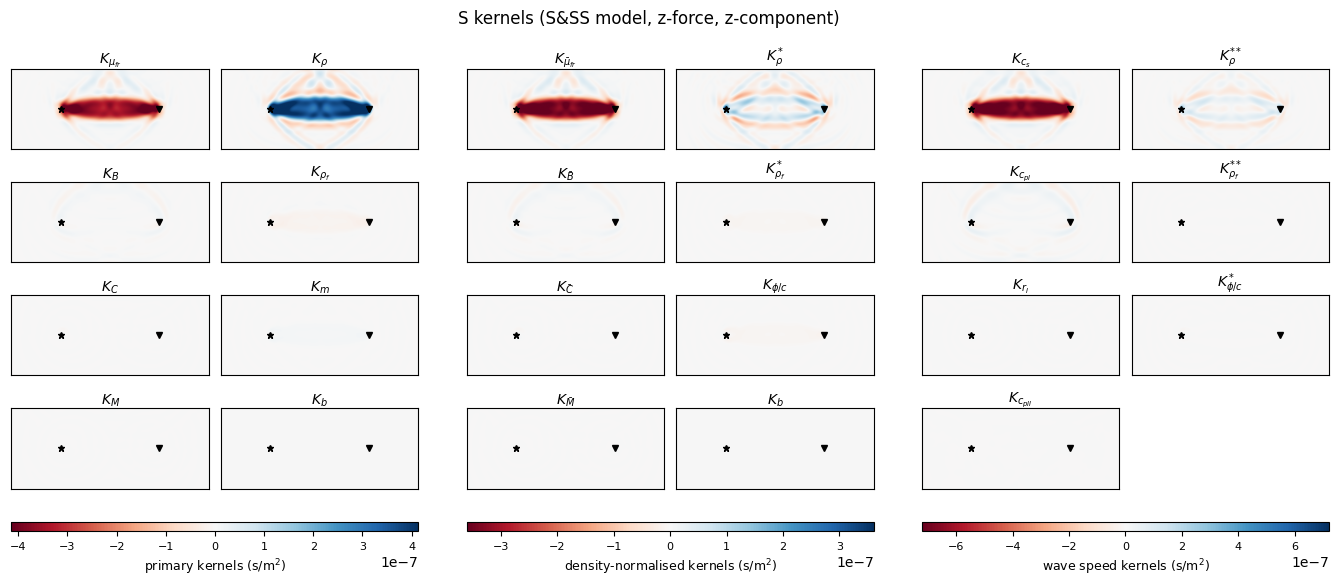

PI: 53 s;  speeds scaled by (1+e) shift T by -1.887 e s (arrival 2.013 s)


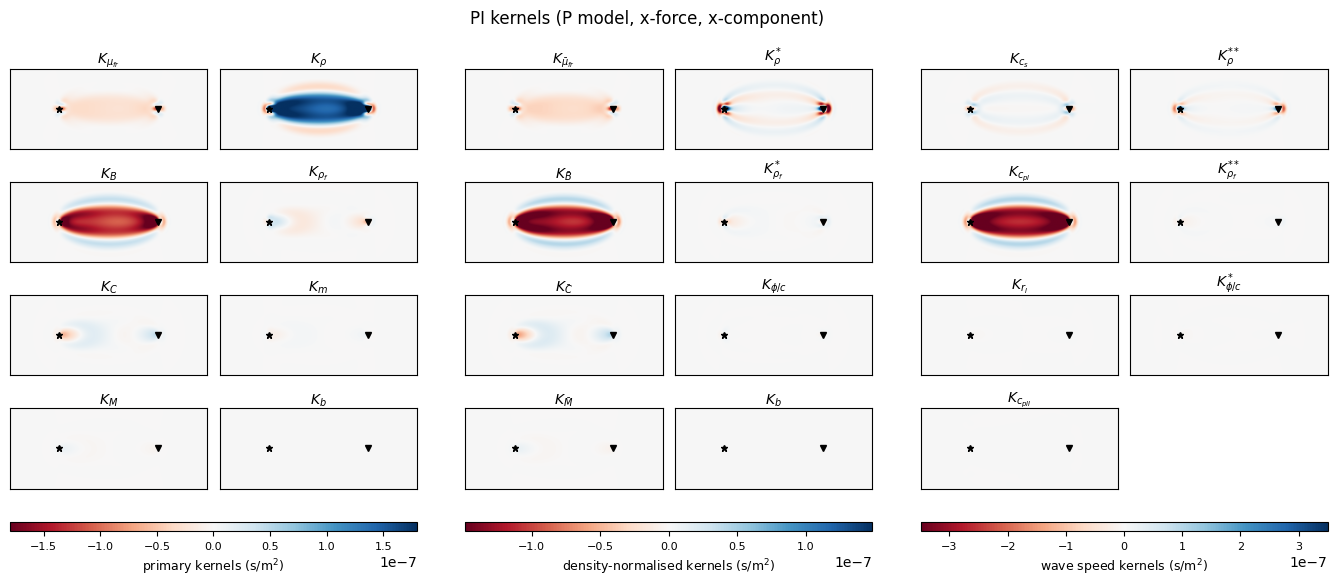

PIIPII: 35 s;  speeds scaled by (1+e) shift T by -3.103 e s (arrival 3.246 s)


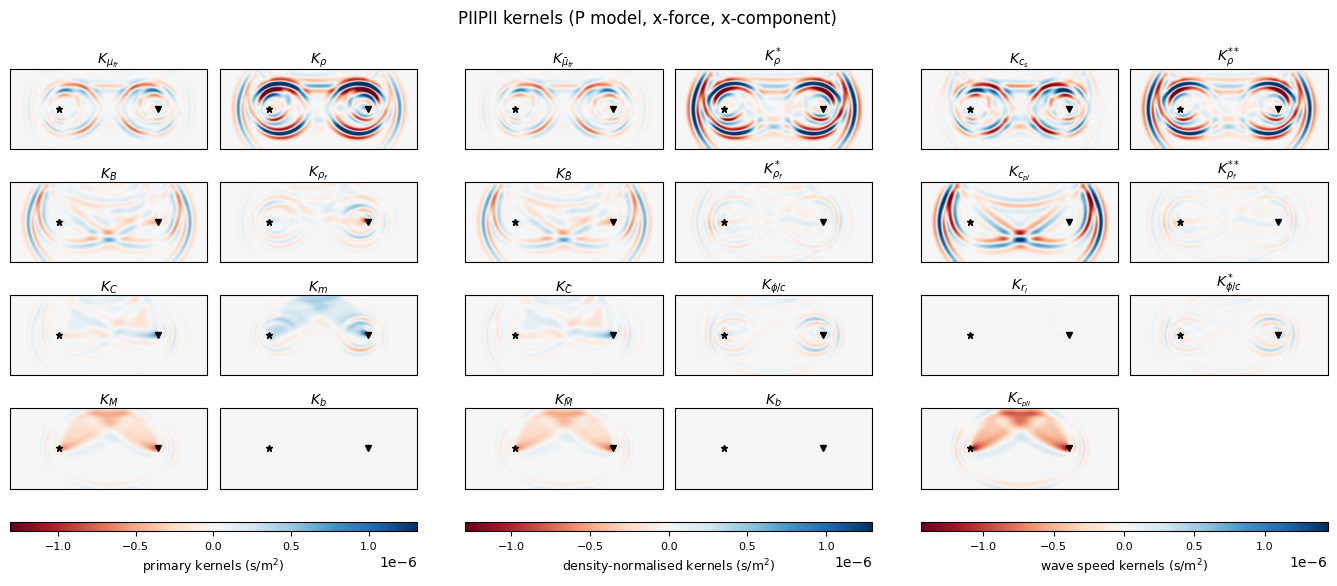

PIS+SPI, viscous: 35 s;  speeds scaled by (1+e) shift T by -3.921 e s (arrival 4.209 s)


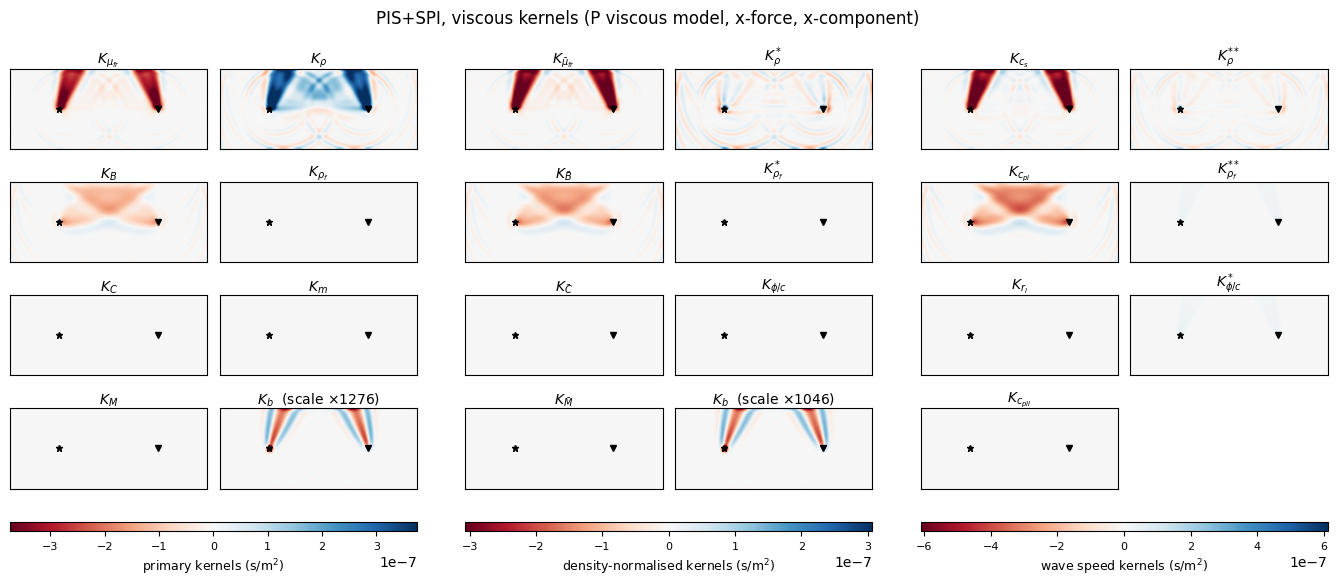

In [6]:
LABELS = {"primary": {"mufr": r"$K_{\mu_{fr}}$", "B": r"$K_B$", "C": r"$K_C$", "M": r"$K_M$", "rho": r"$K_\rho$",
                      "rho_f": r"$K_{\rho_f}$", "m": r"$K_m$", "b": r"$K_b$"},
          "density": {"mubar": r"$K_{\bar\mu_{fr}}$", "Bbar": r"$K_{\bar B}$", "Cbar": r"$K_{\bar C}$", "Mbar": r"$K_{\bar M}$",
                      "rho": r"$K^*_\rho$", "rho_f": r"$K^*_{\rho_f}$", "phic": r"$K_{\phi/c}$", "b": r"$K_b$"},
          "wavespeed": {"cs": r"$K_{c_s}$", "cpI": r"$K_{c_{pI}}$", "rI": r"$K_{r_I}$", "cpII": r"$K_{c_{pII}}$",
                        "rho": r"$K^{**}_\rho$", "rho_f": r"$K^{**}_{\rho_f}$", "phic": r"$K^*_{\phi/c}$"}}
LAYOUT = {"primary": [["mufr", "rho"], ["B", "rho_f"], ["C", "m"], ["M", "b"]],
          "density": [["mubar", "rho"], ["Bbar", "rho_f"], ["Cbar", "phic"], ["Mbar", "b"]],
          "wavespeed": [["cs", "rho"], ["cpI", "rho_f"], ["rI", "phic"], ["cpII", None]]}
SMOOTH = 100.0
zz, xx = np.meshgrid(np.arange(NZ)*DX, np.arange(NX)*DX, indexing="ij")
AWAY = np.ones((NZ, NX), bool)
for x0, z0 in (SRC_XZ, REC_XZ):
    AWAY &= np.hypot(xx - x0, zz - z0) > 300.0

def plot_kernels(fams, title):
    sm = {f: {p: gaussian_filter(k, SMOOTH/DX, mode="reflect") for p, k in d.items()} for f, d in fams.items()}
    fig = plt.figure(figsize=(17, 6))
    gs = fig.add_gridspec(5, 8, height_ratios=[1, 1, 1, 1, 0.12], width_ratios=[1, 1, 0.12]*2 + [1, 1],
                          hspace=0.5, wspace=0.08)
    for bi, fam in enumerate(("primary", "density", "wavespeed")):
        lim = np.percentile(np.concatenate([np.abs(v[AWAY]) for p, v in sm[fam].items() if p != "b"]), 99.5)
        for r_, row in enumerate(LAYOUT[fam]):
            for c_, p in enumerate(row):
                ax = fig.add_subplot(gs[r_, 3*bi + c_])
                if p is None:
                    ax.axis("off"); continue
                k, l, note = sm[fam][p], lim, ""
                if p == "b":
                    kb = np.abs(k[AWAY]).max()
                    if 0 < kb < 0.01*lim:
                        l, note = kb, f"  (scale ×{lim/kb:.0f})"
                im = ax.imshow(k, cmap="RdBu", vmin=-l, vmax=l, aspect="auto", extent=[0, LX/1e3, 0, LZ/1e3])
                ax.plot(SRC_XZ[0]/1e3, (LZ - SRC_XZ[1])/1e3, "k*", ms=5)
                ax.plot(REC_XZ[0]/1e3, (LZ - REC_XZ[1])/1e3, "kv", ms=4)
                ax.set_title(LABELS[fam][p] + note, fontsize=10, pad=2); ax.set_xticks([]); ax.set_yticks([])
                if p != "b" or note == "":
                    keep = im
        cb = fig.colorbar(keep, cax=fig.add_subplot(gs[4, 3*bi:3*bi + 2]), orientation="horizontal")
        cb.set_label({"primary": "primary", "density": "density-normalised", "wavespeed": "wave speed"}[fam]
                     + r" kernels (s/m$^2$)", fontsize=9)
        cb.ax.tick_params(labelsize=8)
    fig.suptitle(title, fontsize=12)
    plt.show()

CASES = [("S", "S&SS", "z", "S"), ("PI", "P", "x", "PI"), ("PIIPII", "P", "x", "PIIPII"),
         ("PIS+SPI, viscous", "P viscous", "x", "PIS")]
RESULTS = {}
for title, model, comp, phase in CASES:
    t0 = time.time()
    c, fams, grads, pieces = kernels(model, comp, phase)
    RESULTS[title] = (model, comp, phase, c, grads, pieces)
    ws = fams["wavespeed"]
    s_speed = sum(ws[p].sum() for p in ("cpI", "cpII", "cs"))*DX**2
    print(f"{title}: {time.time() - t0:.0f} s;  speeds scaled by (1+e) shift T by {s_speed:+.3f} e s "
          f"(arrival {arrivals(c)[phase]:.3f} s)")
    plot_kernels(fams, f"{title} kernels ({model} model, {comp}-force, {comp}-component)")

The printed sum rule is a check of the whole chain: scaling every wave speed by (1 + ε) moves an arrival by
about −εT. It comes out at 0.93–0.96 T, not 1 — the Welch taper is not flat over the pulse, so the
linearised functional returns about 0.94 of a pure time shift (true of the paper's normalisation too).

**What the kernels show (as in the paper):** the S traveltime sees only μ<sub>fr</sub> and density — the
bulk kernels are zero; for P<sub>I</sub> K<sub>B</sub> dominates; the slow wave P<sub>II</sub>P<sub>II</sub>
is governed by K<sub>M</sub> ≈ −K<sub>m</sub>, so K<sub>φ/c</sub> nearly vanishes, and its isochrone rings
come from fast waves scattered into the window; in the viscous model only ρ, μ<sub>fr</sub> and B are
significant, because the fluid barely moves relative to the frame.

## 6. Check against finite differences

The kernel is a derivative, so it must predict what a small perturbation does. Perturb μ by 2 % in a
100 m Gaussian blob on the S kernel and compare the change of the traveltime functional with `Σ K δln μ dA`.

In [7]:
model, comp, phase, c, grads, pieces = RESULTS["S"]
k = COEF.index("mu")
kern = gaussian_filter(grads[k].cpu().numpy()*c[k], 10, mode="reflect")
iz, ix = np.unravel_index(np.argmax(np.where(AWAY & (np.hypot(xx - 5000, zz - 2000) < 1500), np.abs(kern), -1)), kern.shape)
blob = np.exp(-((zz - iz*DX)**2 + (xx - ix*DX)**2)/(2*100.0**2))
pred = float((grads[k].double().cpu().numpy()*c[k]*0.02*blob).sum())
vals = []
for sgn in (1.0, -1.0):
    f = fields(c)
    f[k] = f[k]*torch.from_numpy(1.0 + sgn*0.02*blob).float().to(DEV)
    with torch.no_grad():
        v = record(c, f, comp)[:, 1].double()
    vals.append(float((pieces["w"]*pieces["ud0"]*torch.cumsum(v, 0)*DT).sum()*DT/pieces["n"]))
fd = 0.5*(vals[0] - vals[1])
print(f"blob at x = {ix*DX:.0f} m, depth = {iz*DX:.0f} m:  kernel prediction {pred:+.4e} s,"
      f"  finite difference {fd:+.4e} s,  relative difference {(fd - pred)/pred:+.1e}")

blob at x = 6490 m, depth = 2070 m:  kernel prediction -5.3455e-04 s,  finite difference -5.3461e-04 s,  relative difference +1.2e-04


## Notes

* **No adjoint code was written.** The kernels are `torch.autograd` gradients of a traveltime loss through
  `Biot` — exact for the discretized equations, as the finite-difference check shows.
* **One gradient, any parameterization.** The coefficient gradient is computed once; the primary,
  density-normalised and wave-speed kernels are vector–Jacobian products through their maps, so the
  paper's reparameterizations cost nothing extra.
* **Kernel signs** are those of δT: red (negative) where a stiffer or faster medium makes the arrival earlier.

## Reference

Morency, C., Luo, Y., & Tromp, J. (2009). Finite-frequency kernels for wave propagation in porous media based upon adjoint methods. *Geophysical Journal International, 179*(2), 1148–1168. [doi:10.1111/j.1365-246X.2009.04332.x](https://doi.org/10.1111/j.1365-246X.2009.04332.x) — the models, geometry, misfit and kernel families reproduced here.